## Problem statement

You have just joined a small neighbourhood shop as a data analyst. The owner has a customer list but no idea who the customers really are: "I treat everybody the same, but I feel that some people come every week and spend a lot, and others pass by once in a while". Nobody has told us the groups in advance: there is **no label** to predict. This is **unsupervised learning**, and **K-means** is the classic algorithm to solve it. But K-means has a catch: **you must tell it the number of clusters `k`**, and the data does not say it out loud.

We use the same small dataset as in the step-by-step practice: **15 customers** and **2 variables** (visits per month and average spend). In this exercise everything is already written for you: the K-means algorithm and the **elbow** (inertia) and **silhouette score** for `k = 1..8` with their plots. **Your only job is to read the two plots, decide which `k` they support, and change the variable `chosen_k`** (it starts at `1`, which means "everybody in the same group"). Then you run the rest of the notebook, justify your choice in writing and interpret the clusters you obtain. Your teacher will comment on the best choice in class, after you have made yours.

What each section does:

- **0. Setup** — imports and a fixed seed.
- **1. The customers** — 15 customers, 2 features, written by hand (given).
- **2. Looking at the data** — a scatter plot, before any algorithm.
- **3. K-means toolbox** — our own `kmeans` function and the way the first centroids are picked (given).
- **4. Elbow and silhouette** — inertias, silhouettes and both plots, already done and explained.
- **5. Exercise: choose k** — the only `TODO`: look at the plots and change `chosen_k`; then write your justification.
- **6. Interpreting the clusters** — the final model with your `k`, the profile of each customer type and your names for them.
- **7. Reflection** and **8. Conclusions**.

> **Decision / Why:** everything mechanical is given because the real skill of this practice is **reading evidence, deciding how many clusters to use and defending it**. We also use a **fixed seed** and the same way of picking the first centroids as in the step-by-step practice, so your plots are exactly the ones your classmates and your teacher see. The single cell you must complete starts with `# TODO`; the cells after it work with any value of `chosen_k`.

| Item | Detail |
|---|---|
| **Learning Outcomes** | **LO1** — In-depth knowledge of the concepts, requirements and principles of AI and Machine Learning (unsupervised learning, clusters, centroids, inertia). **LO3** — Detailed understanding of classical and modern AI techniques (K-means and the criteria used to choose `k`: elbow and silhouette). **LO4** — Competence in implementing AI solutions with appropriate languages and tools (reading and running Python, numpy, matplotlib and scikit-learn code). **LO5** — Critical evaluation of the limitations and ethical issues of AI (see the Reflection). |
| **SLR phase** | 2 — Immersion: "I understand how it works" |
| **Activity type** | **Business Case**. A Business Case means analysing and deciding on something that already happened and is documented: here the evidence (the elbow and silhouette curves) is already produced and you have to read it and take a reasoned decision. A Challenge would be generating your own solution to an open problem, and a Simulation would be acting inside an environment that imitates reality; this exercise is neither of them, because you do not build anything new: you analyse existing evidence and defend a decision. |
| **Deliverable** | This notebook with `chosen_k` set, executed, with your written justification and the **Reflection** (section 7), uploaded to Blackboard. |
| **Environment** | Google Colab or a local Python installation, with numpy, pandas, matplotlib and scikit-learn. No downloads are needed: the data is created inside the notebook. |

# 0. Setup

We import the libraries and fix a **seed**. K-means starts from random points, so without a fixed seed two runs could give different results and it would be impossible to compare them.

In [1]:
# If you run this in an environment without the libraries, uncomment the next line:
# %pip install numpy pandas matplotlib scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEED = 8
np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (6, 4)

# 1. The customers

We have the data of **15 customers**, written by hand. Each customer has **two features**:

- `visits_per_month`: how many times the customer came to the shop in a month.
- `avg_spend`: average amount spent per visit, in euros.

The data is stored in a numpy array `X` of shape `(n_customers, n_features)`. Notice that **there is no column with the group**: in unsupervised learning nobody gives us the answer.

> **Decision / Why:** the data is a literal `np.array` so that every student has exactly the same numbers. It is small and two-dimensional on purpose: we can draw everything and the algorithm is exactly the same as with thousands of customers.

In [2]:
X = np.array([
    [2, 18], [3, 25], [2, 30], [4, 22], [3, 20],
    [8, 55], [9, 62], [10, 50], [8, 48], [9, 58],
    [15, 110], [16, 95], [14, 105], [17, 120], [15, 100],
], dtype=float)

feature_names = ["visits_per_month", "avg_spend"]
customers = pd.DataFrame(X, columns=feature_names)
customers.index.name = "customer"

print("Shape of X:", X.shape, "-> 15 customers and 2 features")
customers

Shape of X: (15, 2) -> 15 customers and 2 features


,visits_per_month,avg_spend
customer,,
0,2.0,18.0
1,3.0,25.0
2,2.0,30.0
3,4.0,22.0
4,3.0,20.0
5,8.0,55.0
6,9.0,62.0
7,10.0,50.0
8,8.0,48.0


# 2. Looking at the data

Before running any algorithm, **look at the data**. With two features, a scatter plot is enough. How many groups do you see?

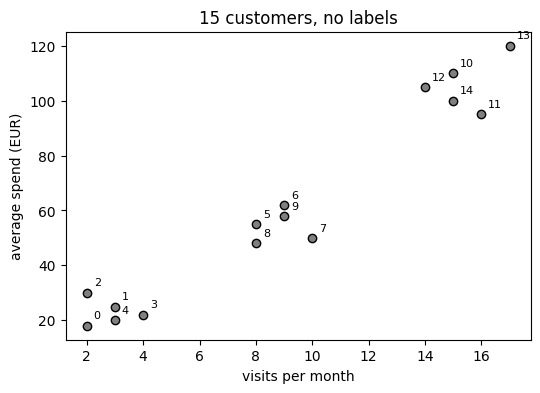

In [3]:
plt.scatter(X[:, 0], X[:, 1], c="gray", edgecolor="black")
for i, (x, y) in enumerate(X):
    plt.annotate(str(i), (x, y), textcoords="offset points", xytext=(5, 5), fontsize=8)
plt.xlabel("visits per month")
plt.ylabel("average spend (EUR)")
plt.title("15 customers, no labels")
plt.show()

Your eyes give you a first idea, but with more customers or more features we could not draw the data at all, so **looking is not enough**. We need a numerical criterion to choose `k`, and that is your task.

# 3. K-means toolbox

These are the functions you built step by step in the previous practice, packed so that you can use them. Nothing to complete here, but read them:

- `pick_initial_centroids(X, k, seed)` — chooses `k` customers at random as the first centroids, always the same ones for a given seed.
- `kmeans(X, k, seed)` — our own K-means from scratch. It returns the centroids, the labels and the **inertia** (sum of squared distances of each point to its centroid).

The elbow and silhouette below are computed with scikit-learn's `KMeans`, started from the centroids given by `pick_initial_centroids`, with a single start (`n_init=1`).

> **Decision / Why:** K-means only finds a local minimum and depends on its first centroids. We use a **fixed seed** (`SEED = 8`) and the **same start as in the step-by-step practice**, so the curves are reproducible and identical to the ones of that practice.

In [4]:
def distances_to_centroids(X, centroids):
    # matrix (n_points, k): distance of every point to every centroid
    return np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)


def update_centroids(X, labels, centroids):
    # every centroid moves to the mean of its points (an empty cluster keeps its position)
    new_centroids = centroids.copy()
    for j in range(len(centroids)):
        members = X[labels == j]
        if len(members) > 0:
            new_centroids[j] = members.mean(axis=0)
    return new_centroids


def compute_inertia(X, centroids, labels):
    # sum of squared distances of each point to the centroid of its cluster
    return ((X - centroids[labels]) ** 2).sum()


def pick_initial_centroids(X, k, seed):
    # k different customers, chosen at random but reproducibly, as the first centroids
    n_customers = len(X)
    return X[np.random.default_rng(seed).choice(n_customers, size=k, replace=False)]


def kmeans(X, k, seed=0, max_iter=100, tol=1e-6):
    # K-means from scratch: k random customers as the first centroids
    centroids = pick_initial_centroids(X, k, seed).astype(float)
    for _ in range(max_iter):
        labels = np.argmin(distances_to_centroids(X, centroids), axis=1)   # assignment
        new_centroids = update_centroids(X, labels, centroids)             # update
        shift = np.linalg.norm(new_centroids - centroids)
        centroids = new_centroids
        if shift < tol:                                                    # convergence
            break
    labels = np.argmin(distances_to_centroids(X, centroids), axis=1)
    return centroids, labels, compute_inertia(X, centroids, labels)



ks = list(range(1, 9))   # the candidate values of k
print("Candidate values of k:", ks)

Candidate values of k: [1, 2, 3, 4, 5, 6, 7, 8]


# 4. Elbow and silhouette

Two classic criteria to choose `k`. Both are computed below for `k = 1..8`, running K-means once for every `k` from the centroids chosen with the seed.

- **Elbow method (inertia):** the inertia always goes down when `k` grows (with `k` equal to the number of points it is zero), so we do not look for the minimum but for the **elbow**: the value of `k` after which adding more clusters improves very little and the curve flattens out.
- **Silhouette score:** for every point it compares how close it is to its own cluster against how close it is to the nearest other cluster. It goes from -1 to 1 and **higher is better**. It is only defined for `k >= 2`, so its plot starts at `k = 2`.

Remember that both are **guides, not truths**: the two criteria may disagree.

In [5]:
inertias = []
silhouettes = []
for k in ks:
    model_k = KMeans(n_clusters=k, init=pick_initial_centroids(X, k, SEED),
                     n_init=1, random_state=SEED).fit(X)
    inertias.append(float(model_k.inertia_))
    if k >= 2:                                   # the silhouette needs at least 2 clusters
        silhouettes.append(float(silhouette_score(X, model_k.labels_)))

print("Inertias (k = 1..8):  ", np.round(inertias, 2))
print("Silhouettes (k = 2..8):", np.round(silhouettes, 3))

Inertias (k = 1..8):   [18546.4   3186.4    600.     532.2    289.75   268.5    178.5    105.75]
Silhouettes (k = 2..8): [0.72  0.779 0.647 0.483 0.451 0.357 0.258]


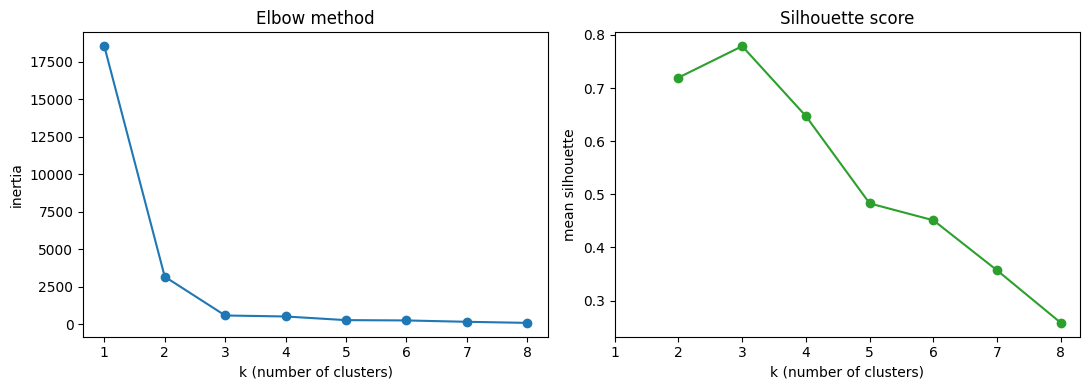

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(ks, inertias, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("k (number of clusters)")
axes[0].set_ylabel("inertia")
axes[0].set_xticks(ks)

axes[1].plot(ks[1:], silhouettes, marker="o", color="tab:green")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k (number of clusters)")
axes[1].set_ylabel("mean silhouette")
axes[1].set_xticks(ks)

plt.tight_layout()
plt.show()

# 5. Exercise: choose k

This is the **only thing you have to do** in the notebook. Look at the two plots of section 4:

- Where is the **elbow** in the left plot?
- For which `k` is the **silhouette** highest in the right plot?
- Do the two criteria agree? Does the number make sense for the shop (how many different campaigns could it run)?

**Your task:** change the value of `chosen_k` (an integer between 1 and 8) in the cell below, then run the rest of the notebook and justify your choice in the markdown cell that follows. Your teacher will comment on the best choice in class.

In [24]:
# TODO: look at the elbow and silhouette plots above and replace the 1 with the k you choose.
chosen_k = 1

**Your answer** (double-click to edit): explain why you chose that `k`. Mention what you see in the elbow, what you see in the silhouette, whether they agree, and what the shop would do with that number of customer types.

> *Your answer:* ...

# 6. Interpreting the clusters

Once we have a `k`, we train K-means with it (same procedure and same start as in section 4) and we **describe each customer type**: the centroids are already in visits and euros, so they can be read directly, and we draw the clusters on the same axes as the data.

These cells work with any value of `chosen_k`.

In [25]:
k_final = int(chosen_k)
final_model = KMeans(n_clusters=k_final, init=pick_initial_centroids(X, k_final, SEED),
                     n_init=1, random_state=SEED).fit(X)
final_labels = final_model.labels_
centroids_original = final_model.cluster_centers_   # already in visits and euros

if k_final >= 2:
    print("Silhouette of the final model:", round(float(silhouette_score(X, final_labels)), 3))
print("Inertia of the final model:", round(float(final_model.inertia_), 2))

profile = pd.DataFrame(centroids_original, columns=feature_names).round(1)
profile["customers"] = np.bincount(final_labels, minlength=k_final)
profile.index.name = "cluster"
display(profile) if "display" in globals() else print(profile)

Inertia of the final model: 18546.4
         visits_per_month  avg_spend  customers
cluster                                        
0                     9.0       61.2         15


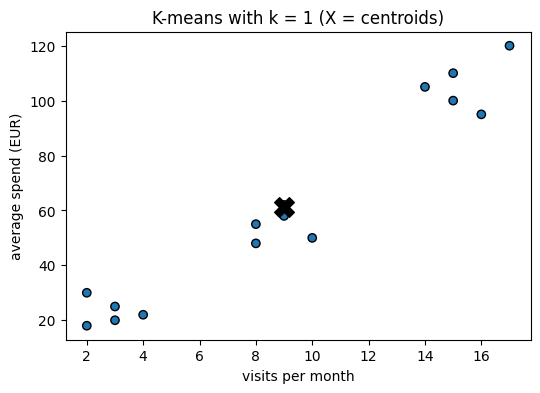

In [26]:
colors = np.array(["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple",
                   "tab:brown", "tab:pink", "tab:gray", "tab:olive", "tab:cyan"])
plt.scatter(X[:, 0], X[:, 1], c=colors[final_labels], edgecolor="black", zorder=2)
plt.scatter(centroids_original[:, 0], centroids_original[:, 1], c="black", marker="X", s=200, zorder=3)
plt.xlabel("visits per month")
plt.ylabel("average spend (EUR)")
plt.title(f"K-means with k = {k_final} (X = centroids)")
plt.show()

**Your answer** (double-click to edit): look at the table of centroids and give a short name and a description to each cluster. Do the clusters make business sense?

> *Your answer:* ...

# 7. Reflection

*Mandatory in the Portfolio.* Answer each question in your own words, below it.

**1. Applicability to other contexts.** In which other problems could you choose `k` with this procedure, and what would change with respect to this case?

> *Your answer:* ...

**2. Strengths and limitations of the technique.** What are the strengths and the limitations of K-means and of the elbow and silhouette criteria you have used?

> *Your answer:* ...

**3. Dataset analysis.** What do you know about this dataset, and what problems could it have if it were real data?

> *Your answer:* ...

**4. Ethical issues.** What ethical problems appear if a segmentation like this is used in a real business?

> *Your answer:* ...

# 8. Conclusions

- In K-means, `k` is not learned: it is **chosen**, and looking at the scatter plot is not enough to choose it. Reading the elbow and the silhouette plots is how we support that choice.
- K-means works with distances, so a variable with much bigger numbers (here `avg_spend`) weighs more than the other. In this exercise we work with the raw data, as in the step-by-step practice; with variables on very different ranges this is a limitation to keep in mind.
- The **elbow** (inertia) and the **silhouette score** give a numerical argument for `k`. They are guides, not truths: they can disagree and the final choice must also make sense for the business.
- K-means depends on its first centroids: a **fixed seed** makes the curves reproducible, but a different start could give a different result.
- The centroids are expressed in the units of the data (visits and euros), so they can be explained directly to the owner.
- Choosing `k` and naming the clusters are human decisions: the algorithm summarises the data, it does not understand the customers.